# RQ3: does a PMI-weighted ingredient graph reveal cuisines? (R4)

**Question.** If we link ingredients that are used together and cluster the graph, do the communities
look like cuisines, and does weighting the edges by PMI do this better than raw co-occurrence counts?

**Course topic:** graph clustering (Louvain, spectral clustering, modularity).
**Outside the course:** pointwise mutual information (PMI) as edge weight. For two ingredients *a*, *b*
in *N* recipes, with p(a) = count(a)/N and p(a,b) = count(a,b)/N:

* lift = p(a,b) / (p(a) p(b)), i.e. how many times more often they appear together than if they were independent
* pmi = log2(lift), 0 for independent ingredients, > 0 for ingredients that attract each other
* npmi = pmi / (−log2 p(a,b)), between −1 and 1, which removes PMI's bias towards rare pairs

Raw counts favour ingredients that are everywhere (salt, butter, sugar): they are linked to everything,
so the graph mostly shows how common an ingredient is, not which ingredients belong together.

**How to run.** From the repo root: `python preprocessing/preprocessing.py` (creates `ingredients_v2`),
then open this notebook from the `graph/` folder. All functions are in `graph/graphs.py` and tested
in `graph/test_graphs.py` (`pytest graph -q`). Runtime about 1 minute.

In [1]:
import pandas as pd
import networkx as nx
from IPython.display import Image, display

import graphs
from run_graph import sweep_all, evaluate, community_table, MIN_LCC_SHARE

pd.set_option("display.max_colwidth", 120)
recipes = graphs.load_recipes()
print(f"{len(recipes):,} recipes, {recipes['cuisine'].notna().sum():,} with a cuisine tag")
recipes["cuisine"].value_counts().head(8)

228,542 recipes, 45,346 with a cuisine tag


cuisine
italian                   7305
southern-united-states    6751
mexican                   6597
asian                     5188
indian                    2645
african                   2579
greek                     2248
french                    2143
Name: count, dtype: int64

## 1. Frequent ingredient pairs

Baskets = the normalised ingredient lists (`ingredients_v2`). We keep the pairs that appear in at least
0.1 % of the recipes. R3's PCY (`pcy/`) finds exactly these pairs (checked: the converted PCY output and
the exact count are identical); `graphs.pairs_from_pcy` reads PCY's files, `graphs.count_pairs` counts
them directly.

In [2]:
pairs = graphs.count_pairs(recipes["ingredients_v2"], min_support=0.001)
weighted = graphs.pmi_weights(pairs)
print(f"{len(pairs):,} frequent pairs between {pd.concat([pairs.item_a, pairs.item_b]).nunique()} ingredients")

5,203 frequent pairs between 572 ingredients


Counts and PMI rank the partners of an ingredient very differently. For *garlic clove*: by count,
the partners are the most common ingredients; by NPMI, they are the ones that really go with garlic.

In [3]:
def partners(item, by, n=8):
    rows = weighted[(weighted.item_a == item) | (weighted.item_b == item)].copy()
    rows["partner"] = rows.item_b.where(rows.item_a == item, rows.item_a)
    return rows.nlargest(n, by)["partner"].tolist()

pd.DataFrame({"by count": partners("garlic clove", "pair_count"), "by npmi": partners("garlic clove", "npmi")})

,by count,by npmi
0,salt,olive oil
1,onion,onion
2,olive oil,tomato paste
3,pepper,extra virgin olive oil
4,water,bay leaf
5,butter,ground cumin
6,parmesan cheese,red pepper flake
7,carrot,dried oregano


## 2. One graph per weighting

Nodes = ingredients, edges = frequent pairs. For lift, pmi and npmi only positive associations (lift > 1)
become edges. The threshold of each weighting is the largest one that keeps at least 90 % of the
ingredients in the largest connected component: we drop as many weak edges as possible without
cutting ingredients off the graph.

count: threshold 263 -> 515 ingredients, 4,436 edges
 lift: threshold 1.49 -> 506 ingredients, 2,938 edges
  pmi: threshold 0.576 -> 506 ingredients, 2,938 edges
 npmi: threshold 0.0546 -> 506 ingredients, 3,148 edges


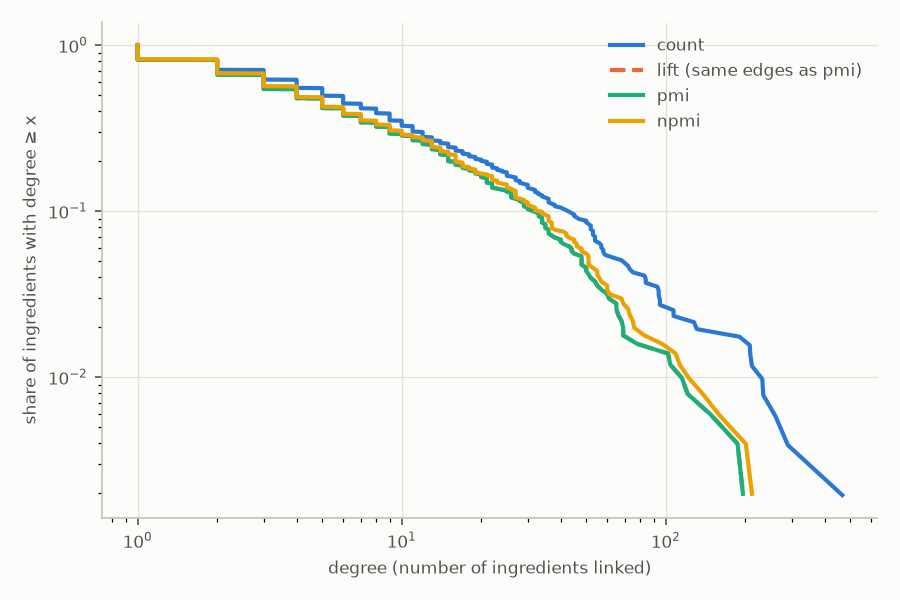

In [4]:
sweep = sweep_all(pairs)
chosen = {}
for w in graphs.WEIGHTS:
    t = graphs.choose_threshold(sweep[sweep.weighting == w], MIN_LCC_SHARE)
    chosen[w] = graphs.ingredient_graph(weighted, w, min_weight=t)
    print(f"{w:>5}: threshold {t:.3g} -> {chosen[w].number_of_nodes()} ingredients, {chosen[w].number_of_edges():,} edges")
display(Image("figures/degree_distribution.png", width=520))

## 3. Communities and cuisines

Each ingredient gets a label when one cuisine accounts for at least 40 % of the tagged recipes that
contain it (and at least 10 such recipes). We compare the communities to these labels with the adjusted
mutual information (AMI: 0 = no better than chance, 1 = identical), and the modularity to two null models
that keep every degree and the edge weights: edges rewired at random, and weights shuffled on the same edges.

In [5]:
labels = graphs.dominant_cuisine(recipes)
rows = []
for w, G in chosen.items():
    for r in evaluate(G, labels):
        rows.append({"weighting": w, **r})
cols = ["weighting", "method", "k", "n_communities", "modularity", "null_rewire_modularity",
        "null_shuffle_modularity", "ami", "null_shuffle_ami", "n_labelled"]
pd.DataFrame(rows)[cols].round(3)

,weighting,method,k,n_communities,modularity,null_rewire_modularity,null_shuffle_modularity,ami,null_shuffle_ami,n_labelled
0,count,louvain,NaN,3.6,0.229,0.329,0.364,0.231,0.090,173
1,count,spectral_eigengap,2.0,2.0,0.230,NaN,NaN,0.144,NaN,173
2,count,spectral_k_louvain,4.0,4.0,0.205,NaN,NaN,0.221,NaN,173
3,lift,louvain,NaN,10.4,0.539,0.330,0.446,0.404,0.215,179
4,lift,spectral_eigengap,2.0,2.0,0.417,NaN,NaN,0.142,NaN,179
5,lift,spectral_k_louvain,10.0,10.0,0.531,NaN,NaN,0.446,NaN,179
6,pmi,louvain,NaN,7.0,0.498,0.260,0.444,0.466,0.193,179
7,pmi,spectral_eigengap,2.0,2.0,0.409,NaN,NaN,0.142,NaN,179
8,pmi,spectral_k_louvain,7.0,7.0,0.458,NaN,NaN,0.398,NaN,179
9,npmi,louvain,NaN,7.2,0.481,0.251,0.422,0.444,0.221,179


**Reading.** With raw counts Louvain finds 3 to 4 communities and the AMI with cuisines is 0.23; the
modularity is even lower than in the rewired null model, because the common ingredients link everything.
With PMI the AMI doubles (0.47), and it falls back to 0.19 when the PMI weights are shuffled on the same
edges: the weights, not the topology, carry the cuisines. Spectral clustering with k from the eigengap
always finds k = 2 (sweet versus savoury); with Louvain's k it comes close to Louvain.

In [6]:
counts = dict(zip(pairs.item_a, pairs.count_a)) | dict(zip(pairs.item_b, pairs.count_b))
community_table(chosen["pmi"], graphs.louvain(chosen["pmi"]), labels, counts, "pmi")

,weighting,community,size,top_ingredients,dominant_cuisine,cuisine_share,n_labelled
0,pmi,0,148,"butter, egg, sugar, flour, milk, brown sugar, all-purpose flour, baking powder, baking soda, vanilla",southern-united-states,0.780488,41
1,pmi,1,125,"onion, pepper, carrot, black pepper, garlic powder, celery, potato, paprika, worcestershire sauce, parsley",southern-united-states,0.395833,48
2,pmi,2,119,"garlic clove, olive oil, garlic, parmesan cheese, lemon juice, chicken broth, extra virgin olive oil, fresh parsley,...",italian,0.731707,41
3,pmi,3,52,"tomato, sour cream, cheddar cheese, mayonnaise, chili powder, red onion, ground cumin, red bell pepper, fresh cilant...",mexican,0.838710,31
4,pmi,4,28,"salt, water, warm water, cinnamon stick, active dry yeast, rice, cooking oil, bread flour, yeast, baby carrot",indian,0.833333,6
5,pmi,5,28,"vegetable oil, green onion, oil, honey, soy sauce, cornstarch, fresh ginger, scallion, ginger, vinegar",asian,1.000000,12
6,pmi,6,6,"orange juice, lemon, orange, orange zest, pineapple juice, orange rind",,0.000000,0


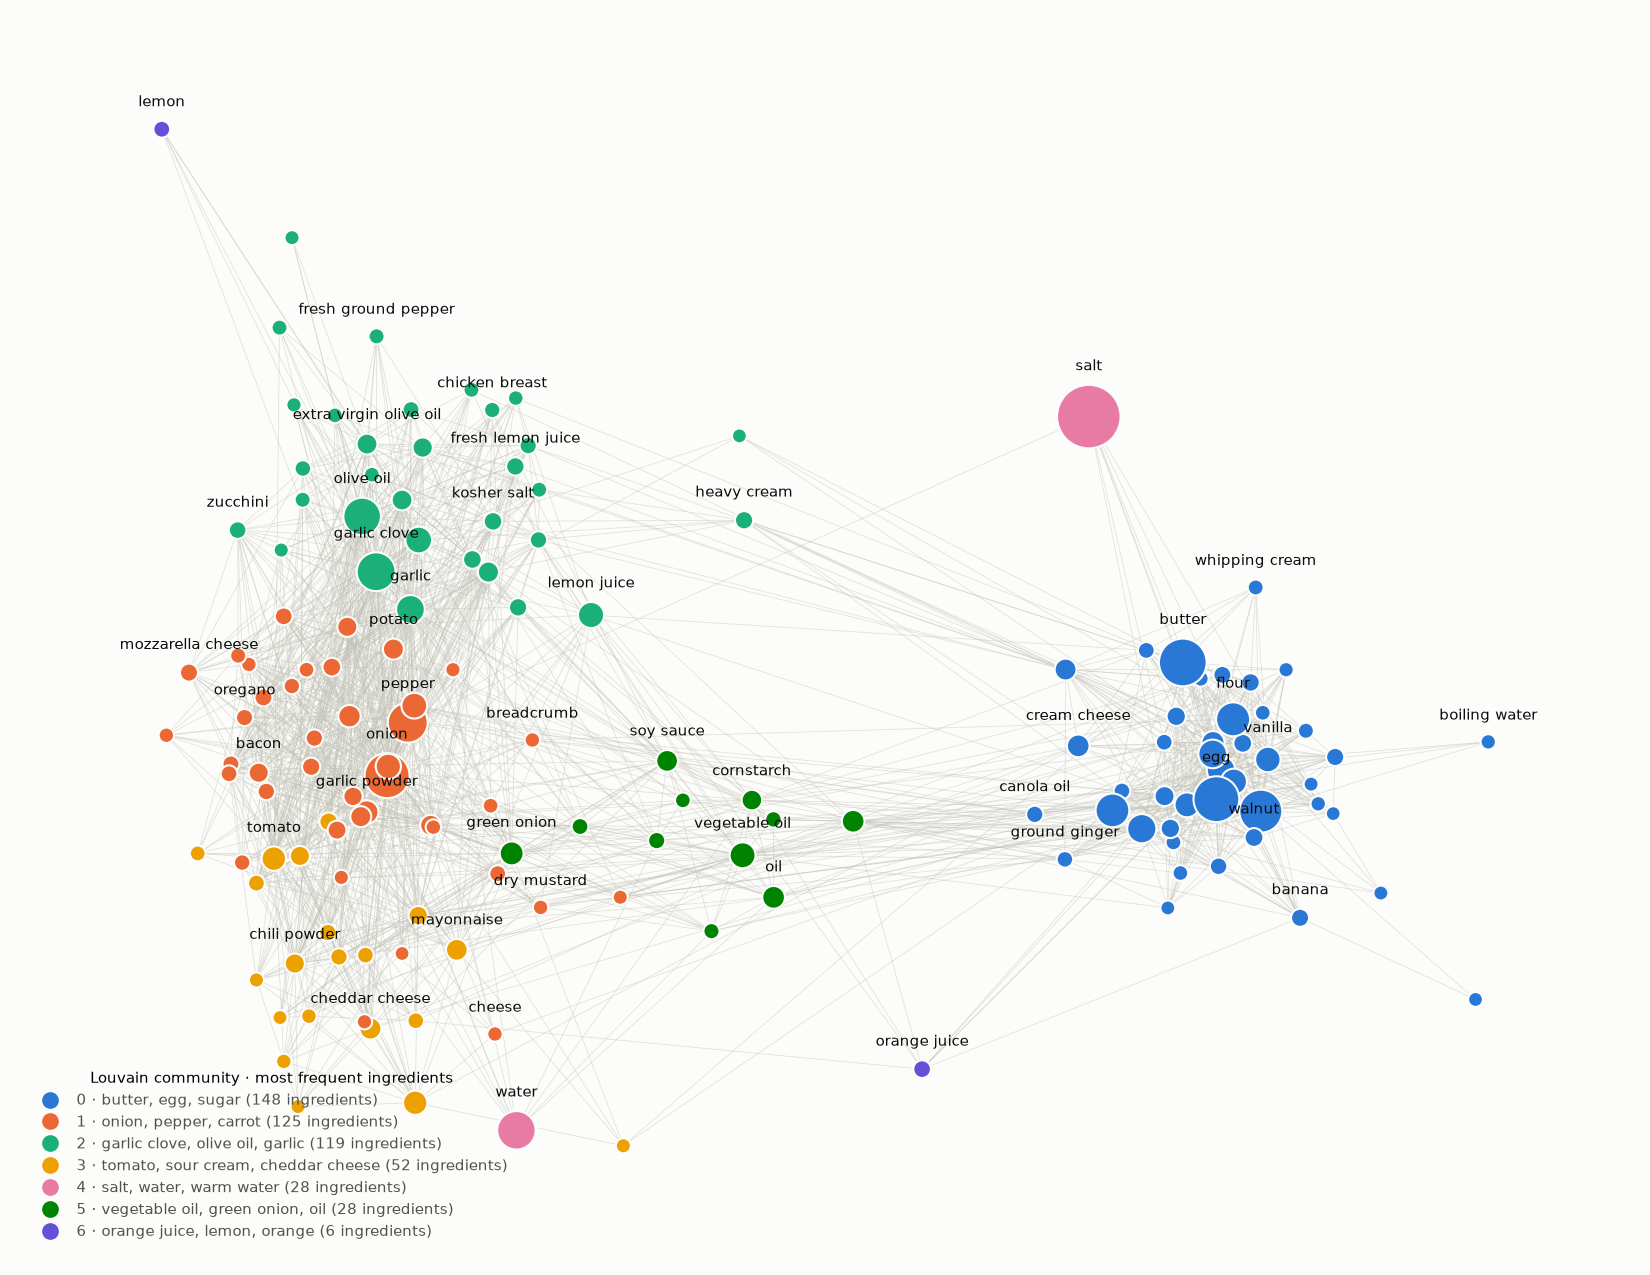

In [7]:
display(Image("figures/graph_pmi.png", width=900))

## 4. Robustness

`python graph/sensitivity.py` changes one parameter at a time (support of the pairs, connectivity rule,
share needed for an ingredient's cuisine) and repeats Louvain on 5 seeds. AMI per setting:

In [8]:
sens = pd.read_csv("results/sensitivity.csv")
sens.pivot_table(index=["varied", "value"], columns="weighting", values="ami")[list(graphs.WEIGHTS)].round(3)

weighting             count   lift    pmi   npmi
varied        value                             
min_lcc_share 0.8000  0.261  0.456  0.459  0.466
              0.9000  0.231  0.404  0.466  0.444
              0.9500  0.219  0.343  0.380  0.378
min_share     0.3000  0.151  0.268  0.310  0.299
              0.4000  0.231  0.404  0.466  0.444
              0.5000  0.290  0.459  0.518  0.516
support       0.0005  0.256  0.402  0.397  0.392
              0.0010  0.231  0.404  0.466  0.444
              0.0020  0.232  0.284  0.294  0.273

In every setting the three PMI-type weightings beat raw counts by a wide margin, so the conclusion
does not depend on our parameter choices. Which of lift, pmi and npmi is best changes with the setting:
the differences between them are small.

## 5. Conclusion and limits

* PMI-type edge weights turn the ingredient graph from "common versus rare" into communities that match
  cuisines: baking, American savoury dishes, Italian / Mediterranean, Mexican, Asian, bread, citrus.
* The cuisine labels are a sanity check, not a ground truth: only about 20 % of the recipes have a cuisine
  tag, and only about 180 of the ~500 ingredients get a dominant cuisine.
* The ingredient normalisation matters: *garlic clove* and *garlic* are still two nodes.